## Wstęp do Uczenia Maszynowego

#### Laboratorium 06

### Zakres laboratorium

- regresja logistyczna: model, interpretacja współczynników, predykcja
- regularyzacja L1 i L2 w regresji logistycznej
- znaczenie skalowania zmiennych dla regularyzacji (z wykorzystaniem `Pipeline` i `ColumnTransformer` z lab05)

### 1. Regresja logistyczna

W modelu regresji liniowej predykcja jest ciągłą wartością (np. cena domu, wzrost):

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p.
$$

Ponieważ wartości prognozowane przez model regresji liniowej są rzeczywiste (od $-\infty$ do $+\infty$), a naszym celem jest klasyfikacja, stosujemy funkcję logistyczną jako przekształcenie:

$$
\sigma(z) = \frac{1}{1 + \mathrm{e}^{-z}} = \frac{\mathrm{e}^{z}}{1 + \mathrm{e}^{z}},
$$

która przyjmuje wartości z przedziału $(0, 1)$. Podstawiając za $z$ kombinację liniową cech, otrzymujemy model regresji logistycznej, który zwraca prawdopodobieństwo $P(Y=1 \mid X)$:

$$
p = P(Y=1 \mid X) = \frac{1}{1 + \mathrm{e}^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p)}} = \frac{\mathrm{e}^{\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p}}{1 + \mathrm{e}^{\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p}}.
$$

Równoważnie, logarytm szans (*logit*) jest równy kombinacji liniowej cech:

$$
\ln\left(\frac{p}{1 - p}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p.
$$

Stąd nazwa modelu: regresję liniową wykonujemy na logarytmie szans.

**Interpretacja współczynników.** Wzrost $x_j$ o 1 (przy ustalonych pozostałych cechach) zwiększa logarytm szans o $\beta_j$, czyli mnoży szanse $\frac{p}{1-p}$ przez $\mathrm{e}^{\beta_j}$ (iloraz szans, *odds ratio*).

**Dopasowanie modelu.** Współczynniki wyznaczamy, minimalizując ujemną log-wiarogodność (*log-loss*):

$$
\mathcal{L}(\boldsymbol{\beta}) = -\sum_{i=1}^{n}\left[y_i\log(p_i) + (1-y_i)\log(1-p_i)\right].
$$

> **Uwaga.** `LogisticRegression()` domyślnie stosuje regularyzację L2 z `C=1.0` (patrz sekcja 2). Aby dopasować model bez regularyzacji, ustawiamy `C=np.inf`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from textwrap import fill

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

-----
##### *Zadanie 1*

Dane `SAheart.data` dotyczą występowania choroby wieńcowej (zmienna `chd`) u mężczyzn z regionu wysokiego ryzyka w RPA. Zmienne objaśniające to m.in. ciśnienie skurczowe (`sbp`), spożycie tytoniu (`tobacco`), cholesterol LDL (`ldl`), występowanie choroby w rodzinie (`famhist`) i wiek (`age`).

a) Dopasuj model regresji logistycznej bez regularyzacji na zbiorze treningowym. Oceń go na zbiorze testowym za pomocą ROC AUC.

b) Zinterpretuj współczynniki przy zmiennych `age` i `famhist`.

c) Dla obserwacji `new_obs` oblicz prawdopodobieństwo `chd = 1` **ręcznie** — na podstawie wyznaczonych współczynników i wzoru na $p$, bez użycia `predict_proba`. Porównaj wynik z `predict_proba`.

> Źródło danych: https://hastie.su.domains/ElemStatLearn/ (*South African Heart Disease*).

In [2]:
SAheart = pd.read_csv('SAheart.data')

# identyfikator nie jest cechą; kodujemy zmienną `famhist` na zmienną binarną
y = SAheart['chd']
X = SAheart.drop(columns=['chd', 'row.names'])
X['famhist'] = X['famhist'].map({'Present': 1, 'Absent': 0})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
X_train.head()

,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age
272,136,1.36,3.16,14.97,1,56,24.98,7.30,24
306,150,14.40,5.04,26.52,1,60,28.84,0.00,45
389,164,5.60,3.17,30.98,1,44,25.99,43.20,53
317,114,1.20,3.98,14.90,0,49,23.79,25.82,26
160,126,1.80,6.22,19.71,0,65,24.81,0.69,31


In [3]:
# a) model regresji logistycznej bez regularyzacji (C=np.inf)
logreg = LogisticRegression(C=np.inf, max_iter=1000)
logreg.fit(X_train, y_train)

print('ROC AUC:', round(roc_auc_score(y_test, logreg.predict_proba(X_test)[:, 1]), 3))

ROC AUC: 0.727


In [4]:
# b) współczynniki i ilorazy szans
pd.DataFrame({
    'beta': logreg.coef_[0],
    'exp(beta)': np.exp(logreg.coef_[0]),
}, index=X.columns).round(3)

,beta,exp(beta)
sbp,-0.001,0.999
tobacco,0.110,1.116
ldl,0.182,1.199
adiposity,0.026,1.027
famhist,0.638,1.892
typea,0.046,1.048
obesity,-0.087,0.917
alcohol,0.001,1.001
age,0.056,1.058


- `age`: $\mathrm{e}^{\hat{\beta}} \approx 1.06$ — każdy dodatkowy rok życia (przy ustalonych pozostałych cechach) zwiększa szanse choroby wieńcowej o ok. 6%.
- `famhist`: $\mathrm{e}^{\hat{\beta}} \approx 1.89$ — występowanie choroby w rodzinie zwiększa szanse choroby prawie dwukrotnie.

In [5]:
# c) nowa obserwacja
new_obs = pd.DataFrame({
    'sbp': [127], 'tobacco': [0], 'ldl': [4.44], 'adiposity': [18], 'famhist': [1],
    'typea': [49], 'obesity': [25], 'alcohol': [0], 'age': [30],
})

In [6]:
# kombinacja liniowa cech: z = beta_0 + beta_1 * x_1 + ... + beta_p * x_p
x = new_obs.iloc[0].values
z = logreg.intercept_[0] + np.sum(logreg.coef_[0] * x)

# funkcja logistyczna
p_manual = 1 / (1 + np.exp(-z))

print('z =', round(z, 4))
print('p (ręcznie):        ', round(p_manual, 4))
print('p (predict_proba):  ', round(logreg.predict_proba(new_obs)[0, 1], 4))

z = -2.0434
p (ręcznie):         0.1147
p (predict_proba):   0.1147


### 2. Regularyzacja regresji logistycznej

Model z wieloma cechami lub dopasowany na niewielkiej liczbie obserwacji łatwo się przeucza: dopasowuje się do szumu w danych treningowych, co zwykle objawia się dużymi wartościami współczynników i dużą wariancją estymatorów. Regularyzacja ogranicza wielkość współczynników — wprowadza niewielkie obciążenie, ale zmniejsza wariancję i często poprawia jakość predykcji na nowych danych.

Do funkcji straty dodajemy karę za duże współczynniki:

$$
\mathcal{L}_\lambda(\boldsymbol{\beta}) = \mathcal{L}(\boldsymbol{\beta}) + \lambda P(\boldsymbol{\beta}),
$$

gdzie:
- dla kary L2: $P(\boldsymbol{\beta}) = \frac{1}{2}\|\boldsymbol{\beta}\|_2^2 = \frac{1}{2}\sum_{j=1}^{p}\beta_j^2$,
- dla kary L1: $P(\boldsymbol{\beta}) = \|\boldsymbol{\beta}\|_1 = \sum_{j=1}^{p}|\beta_j|$.

Wyraz wolny $\beta_0$ zwykle nie podlega karze. L2 zmniejsza wartości współczynników, zaś L1 może wyzerować część z nich (selekcja zmiennych).

W `scikit-learn` parametr `C` jest odwrotnością siły regularyzacji:

$$
C = \frac{1}{\lambda},
$$

więc **mniejsze `C` oznacza silniejszą regularyzację**. 


Rodzaj kary wybieramy parametrem `l1_ratio`: 
- `l1_ratio=0` to kara L2,
- `l1_ratio=1` to kara L1.

W starszych wersjach `scikit-learn` także: `penalty='l2'` / `penalty='l1'`. 

Karę L1 obsługują m.in. solvery `saga` i `liblinear` ([dokumentacja](https://scikit-learn.org/stable/modules/linear_model.html#solvers)). Dla kary L1 będziemy używać `saga`, z dwoma zastrzeżeniami:
- **wyrazu wolnego nie karzemy** — odpowiada on bazowemu logarytmowi szans, a nie złożoności modelu. `saga` go nie regularyzuje, natomiast `liblinear` traktuje wyraz wolny jak dodatkową stałą cechę i nakłada na niego karę. Wpływ tej kary można zmniejszyć, zwiększając parametr `intercept_scaling`;
- **`saga` szybko zbiega tylko dla cech o podobnej skali** — na danych nieskalowanych może nie osiągnąć rozwiązania.

-----
##### *Zadanie 2*

Eksperyment symulacyjny. Wygenerujmy dane w następujący sposób: 
- Niech $n = 200$, $p = 5$.
- $\beta_0 = 1$, $\beta = [2, 1, 0.5, 0.01, 0]$. 
- $x_i \sim N_p(0, I)$ dla $i = 1,2, \dots, n$. 
- $y_i \sim Bern(p_i)$, gdzie $p_i=\frac{\mathrm{e}^{\beta_0 + x_{i\cdot}\beta}}{1 + \mathrm{e}^{\beta_0 + x_{i\cdot}\beta}}$.

a) Dopasuj model regresji logistycznej bez regularyzacji. Porównaj prawdziwe wartości wektora $\beta$ z wyestymowanymi.

b) Dopasuj model regresji logistycznej z regularyzacją $L2$ i wartościami $C = (10, 5, 2, 1, 0.5, 0.1, 0.01, 0.005)$. Jak zmieniają się współczynniki wraz ze wzrostem $\lambda$?

c) Dopasuj model regresji logistycznej z regularyzacją $L1$ i wartościami $C = (10, 5, 2, 1, 0.5, 0.1, 0.01, 0.005)$. Jak zmieniają się współczynniki wraz ze wzrostem $\lambda$?

d) Powtórz eksperyment 500 razy dla modelu logistycznego bez regularyzacji, z regularyzacją $L2$ i parametrem $C=1$ oraz z regularyzacją $L1$ i parametrem $C=1$. Oblicz błąd średniokwadratowy estymatorów współczynników (łącznie z wyrazem wolnym):

$$
\text{MSE} = \frac{1}{K}\sum_{k=1}^{K}\left[(\hat{\beta}_0^{(k)} - \beta_0)^2 + \|\hat{\beta}^{(k)} - \beta\|_2^2\right].
$$

In [7]:
# Symulacja danych wejściowych
rng = np.random.default_rng(123)
n = 200  # liczba obserwacji (wierszy)
p = 5  # liczba zmiennych (kolumn)
beta_0 = 1  # wyraz wolny
beta = np.array([2, 1, 0.5, 0.01, 0])  # współczynniki
X = rng.normal(0, 1, size=(n, p))  # losowanie z wielowymiarowego rozkładu normalnego N(0, I)
z = beta_0 + X @ beta  # kombinacja liniowa cech
probs = 1 / (1 + np.exp(-z))  # p_i = exp(z_i) / (1 + exp(z_i))
y = rng.binomial(1, probs)  # wartości y

In [8]:
# a) model regresji logistycznej bez regularyzacji (C=np.inf)
logreg = LogisticRegression(C=np.inf)
logreg.fit(X, y)

pd.DataFrame({
    'prawdziwe': np.r_[beta_0, beta],
    'wyestymowane': np.r_[logreg.intercept_, logreg.coef_[0]],
}, index=['β0', 'β1', 'β2', 'β3', 'β4', 'β5']).round(3)

,prawdziwe,wyestymowane
β0,1.00,0.548
β1,2.00,1.767
β2,1.00,0.943
β3,0.50,0.211
β4,0.01,0.282
β5,0.00,0.041


Estymatory odbiegają od prawdziwych wartości — przy $n=200$ mają dużą wariancję (np. $\hat{\beta}_4 \approx 0.28$, choć $\beta_4 = 0.01$).

In [9]:
# b)
coefs = []
intercepts = []
C = np.array([10, 5, 2, 1, 0.5, 0.1, 0.01, 0.005])  # zakres wartości C z polecenia

for c in C:
    # model regresji logistycznej z karą L2
    logreg = LogisticRegression(l1_ratio=0, C=c)
    logreg.fit(X, y)
    coefs.append(logreg.coef_[0])  # zapisuję współczynniki
    intercepts.append(logreg.intercept_[0])  # zapisuję wyraz wolny

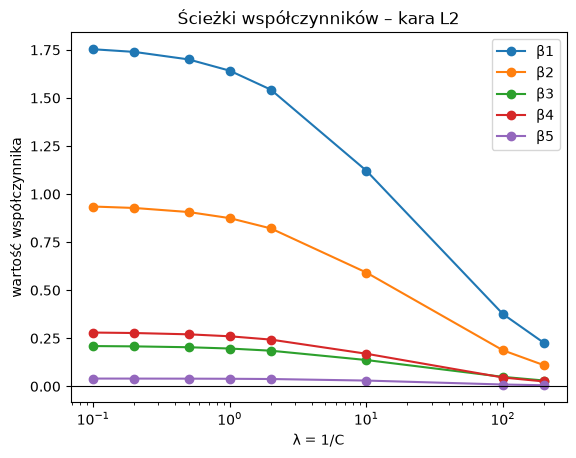

In [10]:
# wykres zależności współczynników od lambda = 1/C (oś w skali logarytmicznej)
fig, ax = plt.subplots()
ax.plot(1 / C, np.array(coefs), marker='o', label=['β1', 'β2', 'β3', 'β4', 'β5'])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xscale('log')
ax.set_xlabel('λ = 1/C')
ax.set_ylabel('wartość współczynnika')
ax.set_title('Ścieżki współczynników – kara L2')
ax.legend()
plt.show()

Wraz ze wzrostem $\lambda$ wszystkie współczynniki maleją co do wartości bezwzględnej i zbliżają się do zera, ale nie są dokładnie zerowane.

In [11]:
# c)
coefs = []
intercepts = []
C = np.array([10, 5, 2, 1, 0.5, 0.1, 0.01, 0.005])  # zakres wartości C z polecenia

for c in C:
    # model regresji logistycznej z karą L1; solver musi obsługiwać karę L1
    logreg = LogisticRegression(l1_ratio=1, C=c, solver='saga')
    logreg.fit(X, y)
    coefs.append(logreg.coef_[0])  # zapisuję współczynniki
    intercepts.append(logreg.intercept_[0])  # zapisuję wyraz wolny

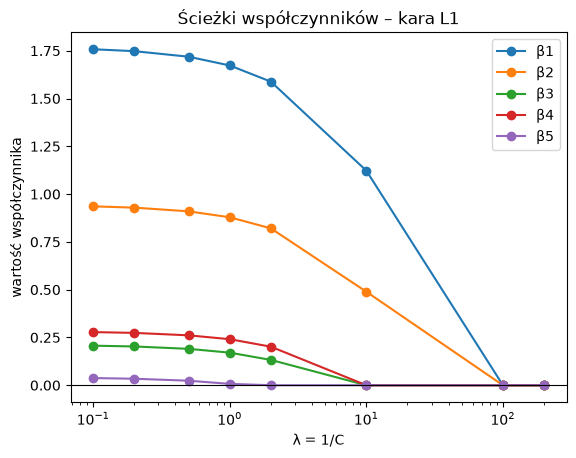

In [12]:
# wykres zależności współczynników od lambda = 1/C (oś w skali logarytmicznej)
fig, ax = plt.subplots()
ax.plot(1 / C, np.array(coefs), marker='o', label=['β1', 'β2', 'β3', 'β4', 'β5'])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xscale('log')
ax.set_xlabel('λ = 1/C')
ax.set_ylabel('wartość współczynnika')
ax.set_title('Ścieżki współczynników – kara L1')
ax.legend()
plt.show()

Przy karze L1 współczynniki kolejno spadają dokładnie do zera — najpierw najmniejsze ($\beta_5$, potem $\beta_3$ i $\beta_4$), a przy bardzo dużym $\lambda$ wszystkie. Kolejność zależy od wyestymowanych, a nie prawdziwych wartości: $\hat{\beta}_4$ jest tu większe od $\hat{\beta}_3$.

In [13]:
# d)
rng = np.random.default_rng(456)
K = 500  # liczba eksperymentów
n = 200
p = 5
beta_0 = 1
beta = np.array([2, 1, 0.5, 0.01, 0])
c = 1


def squared_error(model):
    # błąd kwadratowy całego wektora współczynników (z wyrazem wolnym)
    return np.sum((model.coef_[0] - beta) ** 2) + (model.intercept_[0] - beta_0) ** 2


# miejsce do zapisania wyników
errors = []
errors_l1 = []
errors_l2 = []

for k in range(K):
    # generowanie danych
    X = rng.normal(0, 1, size=(n, p))
    z = beta_0 + X @ beta
    probs = 1 / (1 + np.exp(-z))
    y = rng.binomial(1, probs)

    # model regresji logistycznej bez regularyzacji
    logreg = LogisticRegression(C=np.inf).fit(X, y)
    errors.append(squared_error(logreg))

    # model regresji logistycznej z karą L1
    logreg_l1 = LogisticRegression(l1_ratio=1, C=c, solver='saga').fit(X, y)
    errors_l1.append(squared_error(logreg_l1))

    # model regresji logistycznej z karą L2
    logreg_l2 = LogisticRegression(l1_ratio=0, C=c).fit(X, y)
    errors_l2.append(squared_error(logreg_l2))

print('MSE bez regularyzacji:', np.round(np.mean(errors), 4))
print('MSE L1:', np.round(np.mean(errors_l1), 4))
print('MSE L2:', np.round(np.mean(errors_l2), 4))

MSE bez regularyzacji: 0.3856
MSE L1: 0.2758
MSE L2: 0.2626


Regularyzacja wprowadza obciążenie (współczynniki są „ściągane” do zera), ale zmniejsza wariancję estymatorów. Przy niewielkiej liczbie obserwacji zysk na wariancji przeważa, dlatego MSE modeli z karą jest niższe niż modelu bez regularyzacji.

### 3. Skalowanie a regularyzacja

Kara L1 lub L2 traktuje wszystkie współczynniki jednakowo, a wielkość współczynnika zależy od skali odpowiadającej mu zmiennej. Przykładowo, `credit_amount` (kwota kredytu, wartości rzędu tysięcy) będzie miała bardzo mały współczynnik, nawet jeśli jest ważną cechą. Dlatego przed regularyzacją standaryzujemy cechy numeryczne; poniżej porównamy oba warianty na tych samych danych.

Przygotowanie danych łączymy z modelem w `Pipeline`, tak jak w lab05: `ColumnTransformer` koduje cechy kategoryczne (`OneHotEncoder`) i — w wariancie ze skalowaniem — standaryzuje cechy numeryczne. Wszystkie transformacje są dopasowywane wyłącznie do danych treningowych (a w walidacji krzyżowej — do danych treningowych danego folda).

-----
##### *Zadanie 3*

Wpływ skalowania zmiennych. Korzystając z `Pipeline` i `ColumnTransformer`, dopasuj modele regresji logistycznej (`C=0.03`):
1. z regularyzacją L2 dla danych bez skalowania i dla danych ze skalowaniem cech numerycznych (`StandardScaler`);
2. z regularyzacją L1 dla danych bez skalowania i dla danych ze skalowaniem cech numerycznych (`StandardScaler`).

Porównaj współczynniki oraz ROC AUC na zbiorze testowym.

> **Wskazówka.** Dla modelu L1 ze skalowaniem użyj solvera `saga`. Na danych bez skalowania `saga` nie zbiega, dlatego tam użyj `liblinear` z `intercept_scaling=1000`, aby praktycznie wyłączyć karę na wyrazie wolnym (patrz sekcja 2).

In [14]:
# Wczytanie danych (zbiór German Credit, źródło: OpenML `credit-g`)
df = pd.read_csv('credit-g.csv')
print(df.shape)

# wybranie kilku kolumn
sel_cols = ['age', 'existing_credits', 'duration', 'credit_amount', 'savings_status', 'credit_history', 'class']
df = df[sel_cols].copy()
df.head(10)

(1000, 21)


,age,existing_credits,duration,credit_amount,savings_status,credit_history,class
0,67,2,6,1169,no known savings,critical/other existing credit,good
1,22,1,48,5951,<100,existing paid,bad
2,49,1,12,2096,<100,critical/other existing credit,good
3,45,1,42,7882,<100,existing paid,good
4,53,2,24,4870,<100,delayed previously,bad
5,35,1,36,9055,no known savings,existing paid,good
6,53,1,24,2835,500<=X<1000,existing paid,good
7,35,1,36,6948,<100,existing paid,good
8,61,1,12,3059,>=1000,existing paid,good
9,28,2,30,5234,<100,critical/other existing credit,bad


In [15]:
# kodowanie klas
df['class'] = (df['class'] == 'good').astype(int)

# wybór X i y
X = df.drop(columns='class')
y = df['class']

In [16]:
numerical_features = ['age', 'existing_credits', 'duration', 'credit_amount']
categorical_features = ['savings_status', 'credit_history']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Przygotowanie danych bez skalowania: cechy numeryczne przechodzą bez zmian
preprocessor_raw = ColumnTransformer([
    ('numerical', 'passthrough', numerical_features),
    ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
], verbose_feature_names_out=False)

# Przygotowanie danych ze skalowaniem: standaryzujemy tylko cechy numeryczne,
# zmienne binarne z one-hot encodingu pozostawiamy bez zmian
preprocessor_scaled = ColumnTransformer([
    ('numerical', StandardScaler(), numerical_features),
    ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
], verbose_feature_names_out=False)

In [17]:
# Funkcje pomocnicze


def get_coefs(model):
    # współczynniki regresji logistycznej z nazwami cech po przygotowaniu danych
    names = model.named_steps['pre'].get_feature_names_out()
    return pd.Series(model.named_steps['clf'].coef_[0], index=names)


def test_auc(model):
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])


def plot_coefficient_comparison(coef_raw, coef_scaled, title):
    comparison = pd.DataFrame({
        'bez skalowania': coef_raw,
        'po skalowaniu': coef_scaled,
    })
    comparison = comparison.loc[comparison.abs().max(axis=1).sort_values(ascending=False).index]

    y_pos = np.arange(len(comparison))
    labels = [fill(name, width=26) for name in comparison.index]
    fig, ax = plt.subplots(figsize=(10, max(4, 0.55 * len(comparison))))
    ax.barh(y_pos - 0.2, comparison['bez skalowania'], height=0.4, label='bez skalowania')
    ax.barh(y_pos + 0.2, comparison['po skalowaniu'], height=0.4, label='po skalowaniu')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_yticks(y_pos, labels)
    ax.invert_yaxis()
    ax.set_xlabel('Wartość współczynnika β')
    ax.set_ylabel('Cecha')
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    plt.show()

1. z regularyzacją L2 dla danych bez skalowania i dla danych ze skalowaniem cech numerycznych (`StandardScaler`)

In [18]:
# model regresji logistycznej z karą L2 na danych bez skalowania
model_l2_raw = Pipeline([
    ('pre', preprocessor_raw),
    ('clf', LogisticRegression(l1_ratio=0, C=0.03, max_iter=5000)),
])
model_l2_raw.fit(X_train, y_train)
print('ROC AUC bez skalowania:', round(test_auc(model_l2_raw), 3))

ROC AUC bez skalowania: 0.655


In [19]:
# nazwy cech z wartościami współczynników
coef_l2_raw = get_coefs(model_l2_raw)
coef_l2_raw.sort_values(ascending=False)

credit_history_critical/other existing credit    0.393756
savings_status_no known savings                  0.136821
savings_status_500<=X<1000                       0.118978
credit_history_delayed previously                0.113795
savings_status_>=1000                            0.100042
age                                              0.026001
credit_amount                                   -0.000053
existing_credits                                -0.004834
duration                                        -0.027188
credit_history_existing paid                    -0.064664
credit_history_no credits/all paid              -0.202958
savings_status_<100                             -0.285624
dtype: float64

In [20]:
# model regresji logistycznej z karą L2 na danych ze skalowaniem
model_l2_scaled = Pipeline([
    ('pre', preprocessor_scaled),
    ('clf', LogisticRegression(l1_ratio=0, C=0.03, max_iter=5000)),
])
model_l2_scaled.fit(X_train, y_train)
print('ROC AUC po skalowaniu:', round(test_auc(model_l2_scaled), 3))

ROC AUC po skalowaniu: 0.667


In [21]:
# porównanie współczynników bez skalowania i ze skalowaniem
coef_l2_scaled = get_coefs(model_l2_scaled)
pd.DataFrame({'coef_raw': coef_l2_raw, 'coef_scaled': coef_l2_scaled}).round(4)

,coef_raw,coef_scaled
age,0.0260,0.2249
existing_credits,-0.0048,0.0011
duration,-0.0272,-0.2626
credit_amount,-0.0001,-0.1541
savings_status_500<=X<1000,0.1190,0.1199
savings_status_<100,-0.2856,-0.2819
savings_status_>=1000,0.1000,0.1034
savings_status_no known savings,0.1368,0.1363
credit_history_critical/other existing credit,0.3938,0.4047
credit_history_delayed previously,0.1138,0.1063


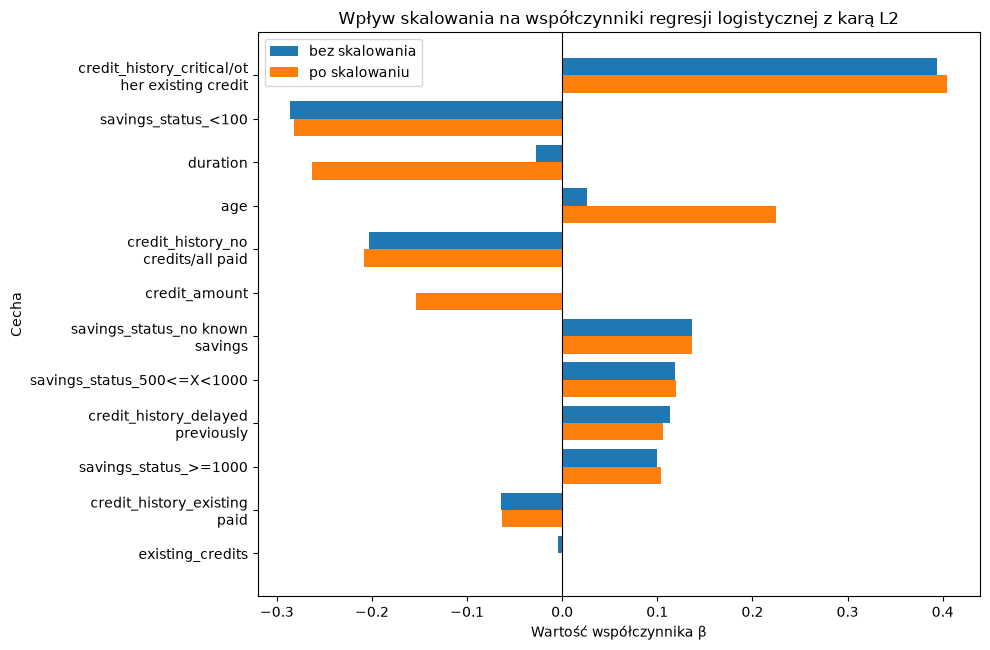

In [22]:
plot_coefficient_comparison(
    coef_l2_raw,
    coef_l2_scaled,
    'Wpływ skalowania na współczynniki regresji logistycznej z karą L2',
)

Bez skalowania współczynniki cech numerycznych zależą od jednostek: `credit_amount` ma współczynnik rzędu $10^{-5}$, a `age` i `duration` około $\pm 0.03$, więc na pierwszy rzut oka wyglądają na nieistotne w porównaniu ze zmiennymi binarnymi. Po standaryzacji współczynnik opisuje zmianę logitu przy wzroście cechy o jedno odchylenie standardowe: `duration` ($\approx -0.26$), `age` ($\approx 0.22$) i `credit_amount` ($\approx -0.15$) mają współczynniki porównywalne ze zmiennymi binarnymi, a kara działa na wszystkie cechy numeryczne jednakowo. Współczynniki zmiennych binarnych (nieskalowanych w obu wariantach) prawie się nie zmieniają. ROC AUC obu modeli jest zbliżone.

2. z regularyzacją L1 dla danych bez skalowania i dla danych ze skalowaniem cech numerycznych (`StandardScaler`)

In [23]:
# model regresji logistycznej z karą L1 na danych bez skalowania
# saga nie zbiega na nieskalowanych danych, dlatego używamy liblinear;
# duże intercept_scaling praktycznie wyłącza karę na wyrazie wolnym
model_l1_raw = Pipeline([
    ('pre', preprocessor_raw),
    ('clf', LogisticRegression(l1_ratio=1, C=0.03, solver='liblinear', intercept_scaling=1000, random_state=42)),
])
model_l1_raw.fit(X_train, y_train)
coef_l1_raw = get_coefs(model_l1_raw)
print('ROC AUC bez skalowania:', round(test_auc(model_l1_raw), 3))
print('Liczba niezerowych współczynników (bez skalowania):', np.count_nonzero(coef_l1_raw))

ROC AUC bez skalowania: 0.587
Liczba niezerowych współczynników (bez skalowania): 3


In [24]:
# model regresji logistycznej z karą L1 na danych ze skalowaniem
model_l1_scaled = Pipeline([
    ('pre', preprocessor_scaled),
    ('clf', LogisticRegression(l1_ratio=1, C=0.03, solver='saga', random_state=42)),
])
model_l1_scaled.fit(X_train, y_train)
coef_l1_scaled = get_coefs(model_l1_scaled)
print('ROC AUC po skalowaniu:', round(test_auc(model_l1_scaled), 3))
print('Liczba niezerowych współczynników (po skalowaniu):', np.count_nonzero(coef_l1_scaled))

ROC AUC po skalowaniu: 0.631
Liczba niezerowych współczynników (po skalowaniu): 2


In [25]:
# porównanie wartości współczynników
pd.DataFrame({'coef_raw': coef_l1_raw, 'coef_scaled': coef_l1_scaled}).round(4)

,coef_raw,coef_scaled
age,0.0285,0.0698
existing_credits,0.0000,0.0000
duration,-0.0244,-0.1964
credit_amount,-0.0001,0.0000
savings_status_500<=X<1000,0.0000,0.0000
savings_status_<100,0.0000,0.0000
savings_status_>=1000,0.0000,0.0000
savings_status_no known savings,0.0000,0.0000
credit_history_critical/other existing credit,0.0000,0.0000
credit_history_delayed previously,0.0000,0.0000


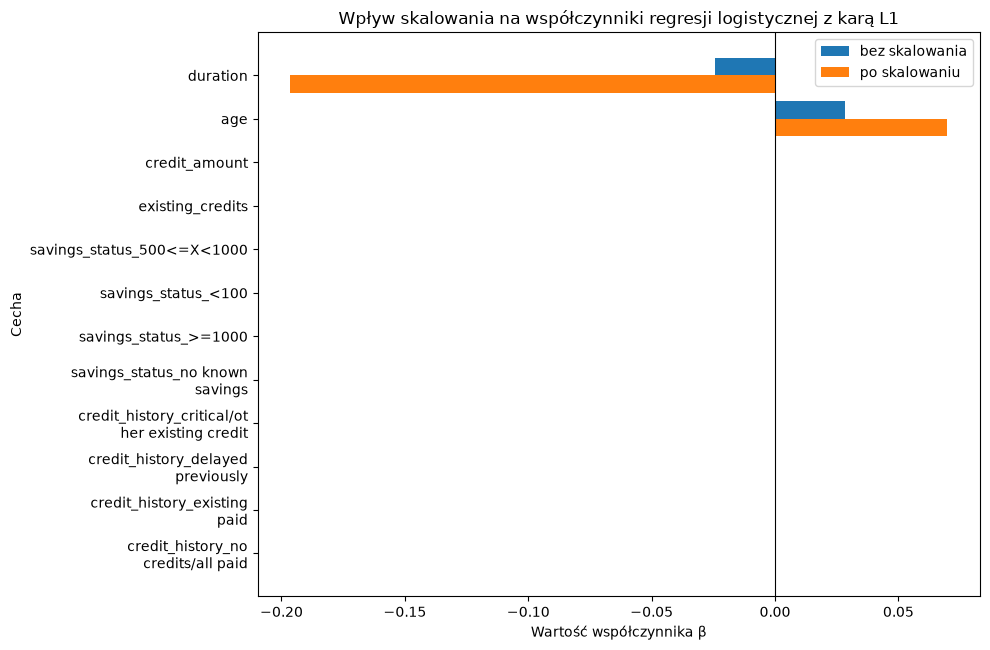

In [26]:
plot_coefficient_comparison(
    coef_l1_raw,
    coef_l1_scaled,
    'Wpływ skalowania na współczynniki regresji logistycznej z karą L1',
)

Kara L1 jest proporcjonalna do $|\beta_j|$, a bez skalowania wielkość współczynnika zależy od jednostek cechy. Przy `C=0.03` oba modele zerują wszystkie zmienne binarne, ale różnią się cechami numerycznymi:
- bez skalowania model zachowuje `credit_amount` — jej współczynnik jest rzędu $10^{-4}$, więc kara za niego jest znikoma i cecha praktycznie nie może zostać wyzerowana, niezależnie od tego, jak jest ważna;
- po skalowaniu wszystkie cechy numeryczne są karane jednakowo: `credit_amount` zostaje wyzerowana, a zostają `duration` i `age`.

Bez skalowania o tym, które cechy zostaną wybrane, decydują więc jednostki, a nie siła związku ze zmienną objaśnianą.

> Różnica w ROC AUC (0.587 i 0.631) pochodzi z pojedynczego podziału na zbiór treningowy i testowy, więc nie należy wyciągać z niej zbyt daleko idących wniosków.

#### Jak dobrać `C`?

W tym zadaniu wartość `C=0.03` dobraliśmy tak, aby efekt skalowania był dobrze widoczny. W praktyce `C` (oraz rodzaj kary) to hiperparametry, które dobieramy walidacją krzyżową na zbiorze treningowym — tak jak `max_depth` drzewa w lab04 i lab05. Wystarczy przekazać cały pipeline do `GridSearchCV`, np. z siatką `{'clf__C': np.logspace(-3, 2, 11)}`; skalowanie jest wtedy dopasowywane osobno w każdym foldzie. Alternatywą jest `LogisticRegressionCV`, które samo przeszukuje wartości `C` z użyciem walidacji krzyżowej.